In [2]:
import numpy as np
from scipy.io import loadmat
import warnings
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter
from scipy.optimize import curve_fit

In [3]:
!pip install pandas
!pip install resonator_tools

Defaulting to user installation because normal site-packages is not writeable
Defaulting to user installation because normal site-packages is not writeable


In [4]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import root, least_squares
from scipy.special import ellipk
from scipy.constants import mu_0, epsilon_0
from resonator_tools import circuit

In [5]:
import os
os.chdir(r"C:\Users\chowdhf4\.vscode\Tunable-Coupler\TC-Main-001")   # paste your copied path here
print(os.getcwd())
print(os.listdir()) 

C:\Users\chowdhf4\.vscode\Tunable-Coupler\TC-Main-001
['Freq_s1.mat', 'Freq_s2.mat', 'Freq_s3.mat', 'I1_s1.mat', 'I1_s2.mat', 'I1_s3.mat', 'S21_mag_s1.mat', 'S21_mag_s2.mat', 'S21_mag_s3.mat', 'S21_phase_s1.mat', 'S21_phase_s2.mat', 'S21_phase_s3.mat', 'TC-ABCD.ipynb', 'TC-Main-001-A-fit-all.mat', 'Tc-Main-001-F-fit-test1.mat', 'TC-Main-001-f0-all.mat', 'TC-Main-001-f0-fit-all.mat', 'TC-Main-001-Fit-v2.ipynb', 'TC-Main-001-Fit-v3.ipynb', 'TC-Main-001-Fit-v4.ipynb', 'TC-Main-001-Fit-v5.ipynb', 'TC-Main-001-Fit-v6.ipynb', 'TC-Main-001-Fit-v7.ipynb', 'TC-Main-001-Fit.ipynb', 'TC-Main-001-Freq-Unfiltered.mat', 'TC-Main-001-I-fit-test1.mat', 'TC-Main-001-I1-fit-all.mat', 'TC-Main-001-I1-sp-lp-unfiltered.mat', 'TC-Main-001-Q-ext-fit-all.mat', 'TC-Main-001-Q-int-fit-all.mat', 'TC-Main-001-Q-L-fit-all.mat', 'TC-Main-001-resonator-tools-fit-results.csv', 'TC-Main-001-S21-dB-sp-lp-unfiltered.mat', 'TC-Main-001-S21-Fit-test1.mat', 'TC-Main-001-S21-phase-Fit-test1.mat', 'TC-Main-001-S21-phase-sp-l

In [6]:
File_S21_mag_s1     = 'S21_mag_s1.mat'
File_S21_mag_s2     = 'S21_mag_s2.mat'
File_S21_mag_s3     = 'S21_mag_s3.mat'
File_S21_phase_s1   = 'S21_phase_s1.mat'
File_S21_phase_s2   = 'S21_phase_s2.mat'
File_S21_phase_s3   = 'S21_phase_s3.mat'
FILE_FREQ_s1        = 'Freq_s1.mat'
FILE_FREQ_s2        = 'Freq_s2.mat'
FILE_FREQ_s3        = 'Freq_s3.mat'
FILE_CURRENT_s1     = 'I1_s1.mat'
FILE_CURRENT_s2     = 'I1_s2.mat'
FILE_CURRENT_s3     = 'I1_s3.mat'


Mat_Freq_s1     = loadmat(FILE_FREQ_s1, squeeze_me=True)
Mat_Freq_s2     = loadmat(FILE_FREQ_s2, squeeze_me=True)
Mat_Freq_s3     = loadmat(FILE_FREQ_s3, squeeze_me=True)
Mat_Current_s1  = loadmat(FILE_CURRENT_s1, squeeze_me=True)
Mat_Current_s2  = loadmat(FILE_CURRENT_s2, squeeze_me=True)
Mat_Current_s3  = loadmat(FILE_CURRENT_s3, squeeze_me=True)
Mat_mag_s1  = loadmat(File_S21_mag_s1, squeeze_me=True)
Mat_mag_s2  = loadmat(File_S21_mag_s2, squeeze_me=True)
Mat_mag_s3  = loadmat(File_S21_mag_s3, squeeze_me=True)
Mat_phase_s1 = loadmat(File_S21_phase_s1, squeeze_me=True)
Mat_phase_s2 = loadmat(File_S21_phase_s2, squeeze_me=True)
Mat_phase_s3 = loadmat(File_S21_phase_s3, squeeze_me=True)

#Mat_F0_Guess = loadmat(File_F0_Guess, squeeze_me=True)
S21_mag_f1 = Mat_mag_s1['S21_filtered_fit_1'] 
S21_mag_f2 = Mat_mag_s2['S21_filtered_fit_2']
S21_mag_f3 = Mat_mag_s3['S21_filtered_fit_3']
S21_phase_f1 = Mat_phase_s1['S21_filtered_phase_fit_1']
S21_phase_f2 = Mat_phase_s2['S21_filtered_phase_fit_2']
S21_phase_f3 = Mat_phase_s3['S21_filtered_phase_fit_3']
Freq_f1 = Mat_Freq_s1['Freq_filtered_f1']
Freq_f2 = Mat_Freq_s2['Freq_filtered_f2']
Freq_f3 = Mat_Freq_s3['Freq_filtered_f3']
I1_s1  = Mat_Current_s1['I1_s1']
I1_s2  = Mat_Current_s2['I1_s2']
I1_s3  = Mat_Current_s3['I1_s3']
# f0_guess = Mat_F0_Guess['dips']
# Mat_phase_s1
#Mat_Complex
S21_complex_f1 = 10**(S21_mag_f1/20) * np.exp(1j * S21_phase_f1)
S21_complex_f2 = 10**(S21_mag_f2/20) * np.exp(1j * S21_phase_f2)
S21_complex_f3 = 10**(S21_mag_f3/20) * np.exp(1j * S21_phase_f3)
S21_complex_f1.shape[1], S21_complex_f2.shape[1], S21_complex_f3.shape[1]
# Mat_phase_s2

(101, 19, 96)

In [7]:
print("Freq_f1:", Freq_f3.shape)
print("S21_mag_f1:", S21_mag_f1.shape, " S21_phase_f1:", S21_phase_f1.shape)
print("S21_complex_f1:", S21_complex_f1.shape)
print("I1_s1:", I1_s1.shape)

Freq_f1: (901,)
S21_mag_f1: (901, 101)  S21_phase_f1: (901, 101)
S21_complex_f1: (901, 101)
I1_s1: (101,)


In [8]:
fit_results_dict = {}
ports_dict = {}   # optional, if you want to re-plot a specific trace later without refitting
fit_results_dict_2 = {}
ports_dict_2 = {}   # optional, if you want to re-plot a specific trace later without refitting
fit_results_dict_3 = {}
ports_dict_3 = {}   # optional, if you want to re-plot a specific
for i in range(S21_complex_f1.shape[1]):
    f_sub = Freq_f1
    s_sub = S21_complex_f1[:, i]

    port_i = circuit.notch_port(f_sub, s_sub)
    try:
        port_i.autofit(electric_delay=0)
        fit_results_dict[i] = port_i.fitresults
        ports_dict[i] = port_i
    except Exception as e:
        print(f"I1={I1_s1[i]:.3g} mA: fit failed ({e})")
        fit_results_dict[i] = None


for i in range(S21_complex_f2.shape[1]):
    f_sub = Freq_f2
    s_sub = S21_complex_f2[:, i]

    port_i = circuit.notch_port(f_sub, s_sub)
    try:
        if i == 1:
            Ql_guess = 80
            port_i.autofit(electric_delay=0, fr_guess= 5.12e9, Ql_guess=Ql_guess)
            fit_results_dict_2[i] = port_i.fitresults
            ports_dict_2[i] = port_i
        elif i == 2:
            Ql_guess = 65
            port_i.autofit(electric_delay=0, fr_guess= 5.02578e9, Ql_guess=Ql_guess)
            fit_results_dict_2[i] = port_i.fitresults
            ports_dict_2[i] = port_i
        else:
            port_i.autofit(electric_delay=0)
            fit_results_dict_2[i] = port_i.fitresults
            ports_dict_2[i] = port_i
    except Exception as e:
        print(f"I1={I1_s2[i]:.3g} mA: fit failed ({e})")
        fit_results_dict_2[i] = None

for i in range(S21_complex_f3.shape[1]):
    f_sub = Freq_f3
    s_sub = S21_complex_f3[:, i]

    port_i = circuit.notch_port(f_sub, s_sub)
    try:
        port_i.autofit(electric_delay=0)
        fit_results_dict_3[i] = port_i.fitresults
        ports_dict_3[i] = port_i
    except Exception as e:
        print(f"I1={I1_s3[i]:.3g} mA: fit failed ({e})")
        fit_results_dict_3[i] = None

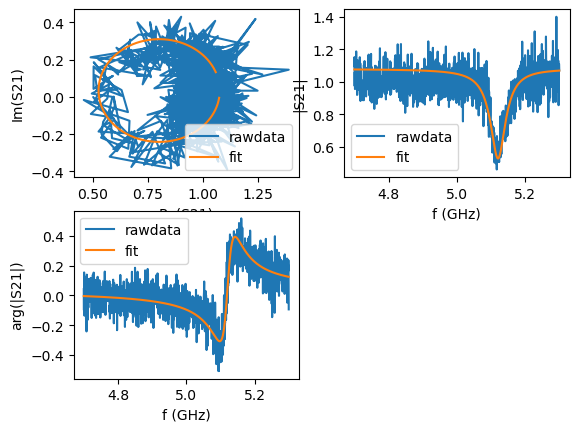

0
I1=0.35 mA: f0=5120659817.302081 Hz, Ql=79.7


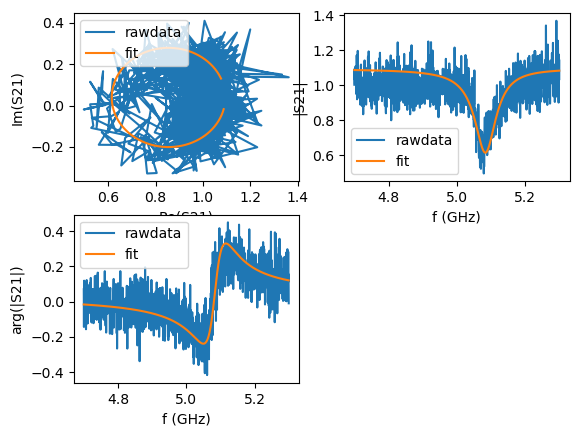

1
I1=0.36 mA: f0=5084361586.231178 Hz, Ql=58


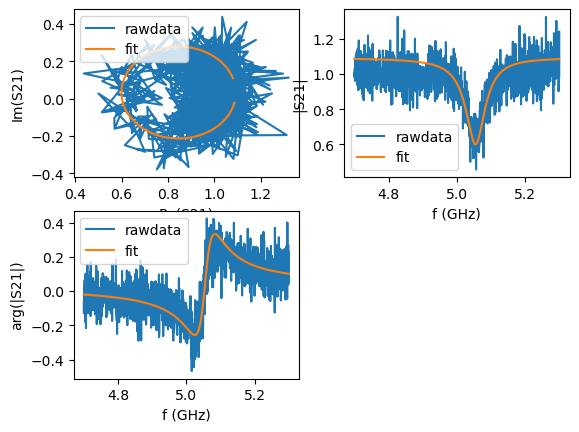

2
I1=0.37 mA: f0=5055018447.216117 Hz, Ql=63.9


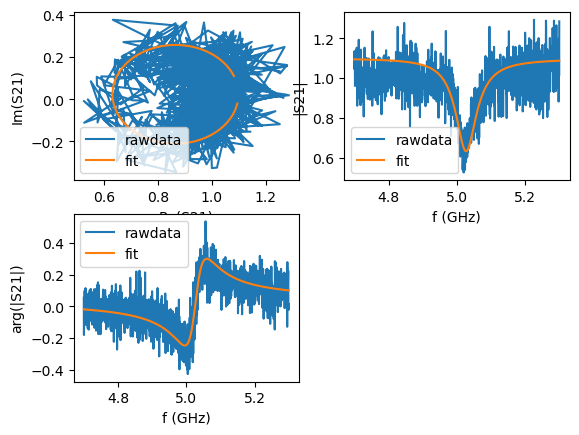

3
I1=0.38 mA: f0=5025785863.067158 Hz, Ql=59.2


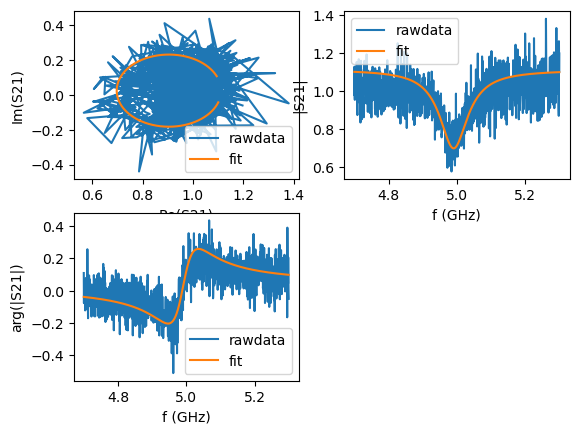

4
I1=0.39 mA: f0=4989610877.006032 Hz, Ql=44.4


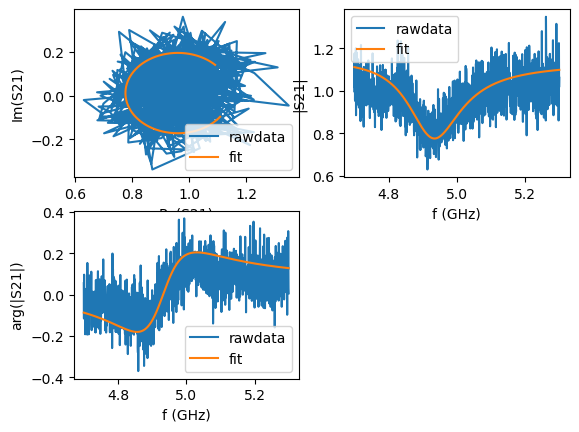

5
I1=0.4 mA: f0=4922397791.288939 Hz, Ql=23.7


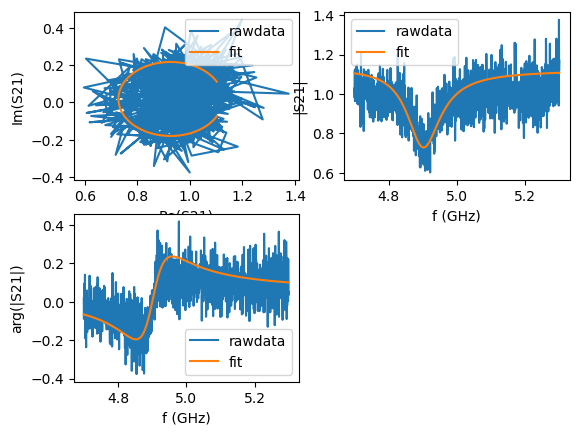

6
I1=0.41 mA: f0=4897759243.202234 Hz, Ql=37.3


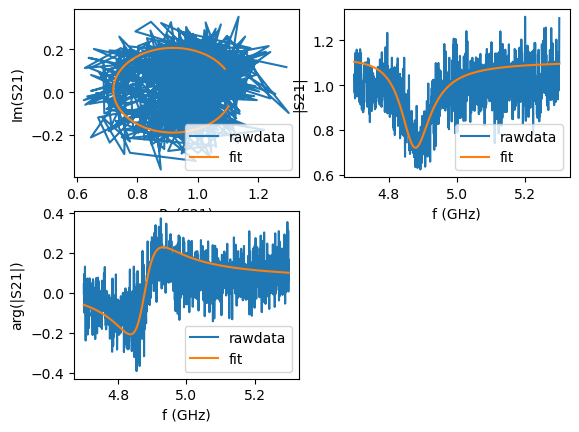

7
I1=0.42 mA: f0=4871312059.686412 Hz, Ql=42


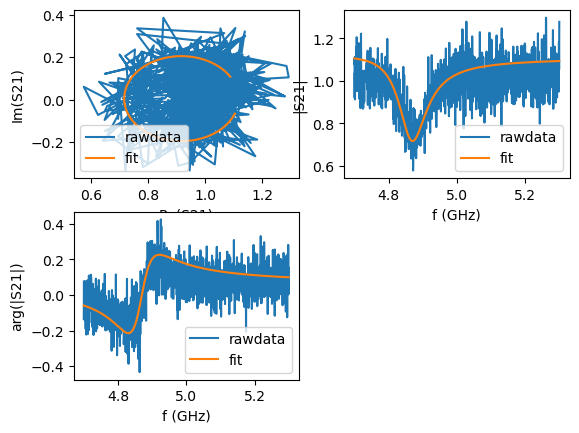

8
I1=0.43 mA: f0=4862171055.361324 Hz, Ql=44.2


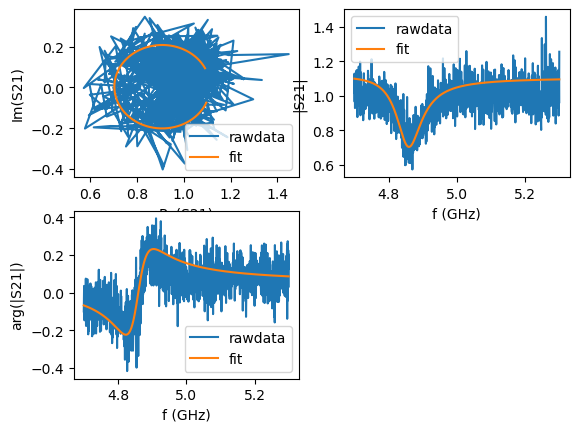

9
I1=0.44 mA: f0=4853634209.640145 Hz, Ql=48.5


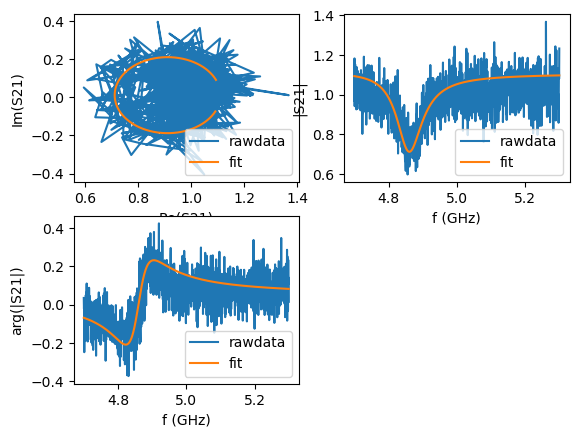

10
I1=0.45 mA: f0=4856240295.818571 Hz, Ql=47.8


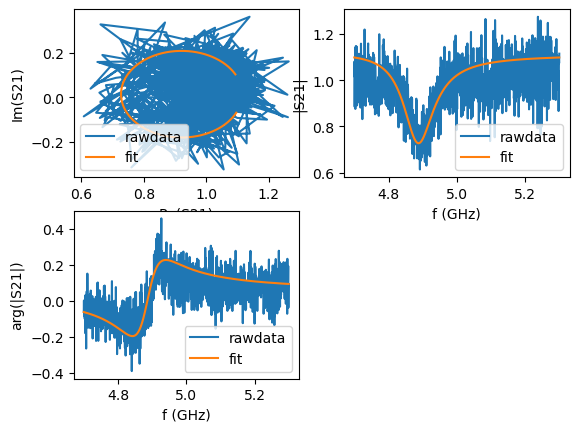

11
I1=0.46 mA: f0=4882191636.811440 Hz, Ql=40.8


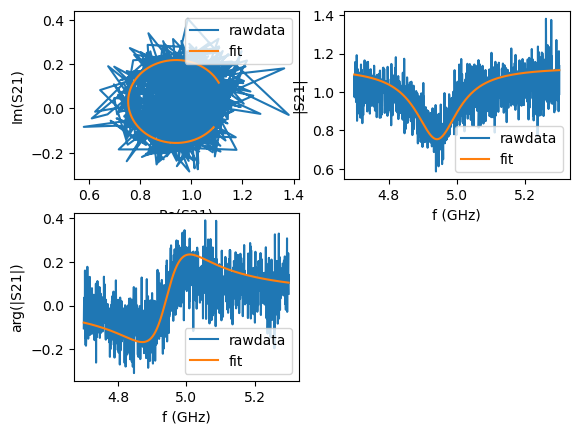

12
I1=0.47 mA: f0=4942777750.583935 Hz, Ql=29.1


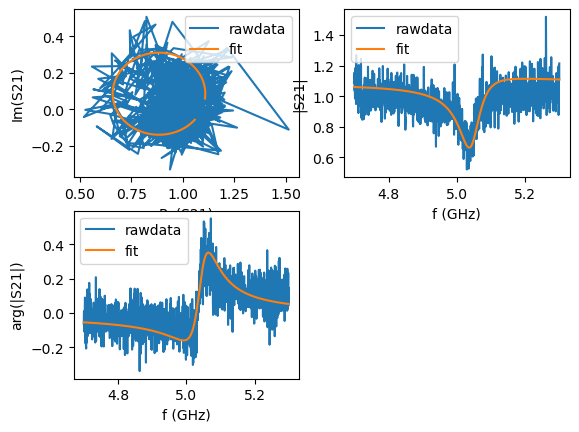

13
I1=0.48 mA: f0=5047385865.005755 Hz, Ql=60.4


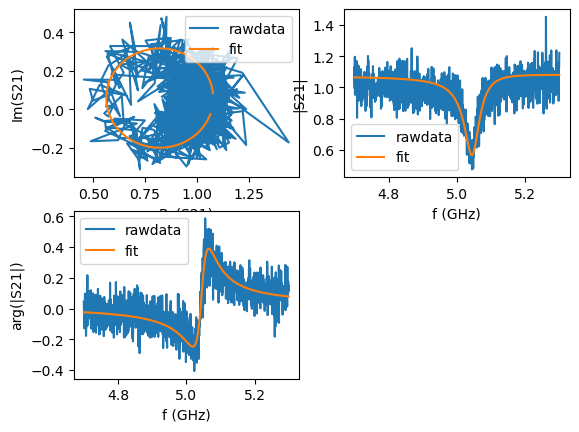

14
I1=0.49 mA: f0=5047228999.832433 Hz, Ql=79.5


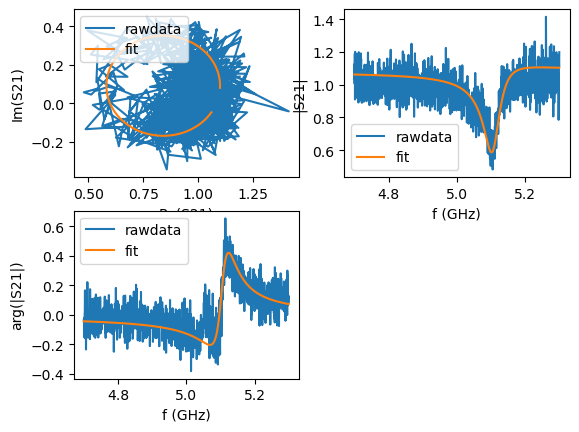

15
I1=0.5 mA: f0=5109827462.571961 Hz, Ql=75.6


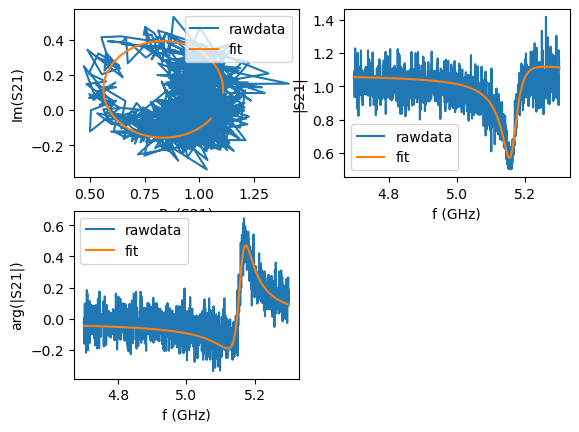

16
I1=0.51 mA: f0=5164072269.488445 Hz, Ql=83.3


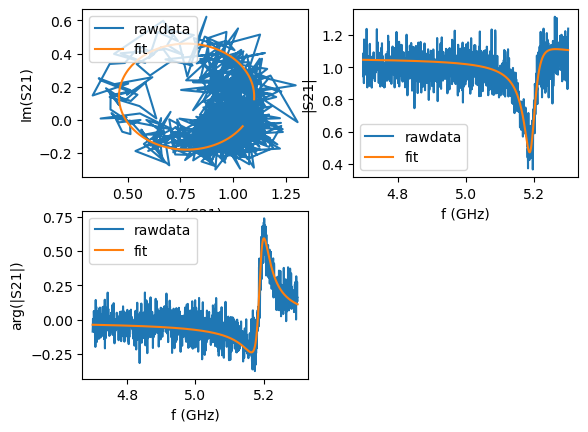

17
I1=0.52 mA: f0=5194973805.741183 Hz, Ql=109


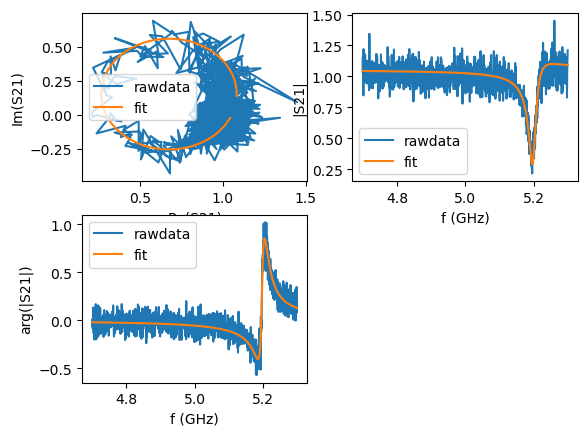

18
I1=0.53 mA: f0=5201416403.981080 Hz, Ql=153


In [9]:
for i in range(S21_complex_f2.shape[1]):
    if fit_results_dict_2[i] is not None:
        ports_dict_2[i].plotall()
        print(i)
        print(f"I1={I1_s2[i]:.3g} mA: f0={fit_results_dict_2[i]['fr']:.6f} Hz, Ql={fit_results_dict_2[i]['Ql']:.3g}")

In [10]:
fr_1 = np.full(len(fit_results_dict), np.nan)
Qi_1 = np.full(len(fit_results_dict), np.nan)
Qc_1 = np.full(len(fit_results_dict), np.nan)
Ql_1 = np.full(len(fit_results_dict), np.nan)
phi_0_1 = np.full(len(fit_results_dict), np.nan)

for i, r in enumerate(fit_results_dict.values()):
    if r is None:
        continue
    fr_1[i] = r['fr']
    Qi_1[i] = r['Qi_dia_corr']   # key names vary slightly by version — check port.fitresults.keys()
    Qc_1[i] = r['absQc']   # key names vary slightly by version — check port.fitresults.keys()
    Ql_1[i] = r['Ql']
    phi_0_1[i] = r['phi0']

In [11]:
fr_2 = np.full(len(fit_results_dict_2), np.nan)
Qi_2 = np.full(len(fit_results_dict_2), np.nan)
Qc_2 = np.full(len(fit_results_dict_2), np.nan)
Ql_2 = np.full(len(fit_results_dict_2), np.nan)
phi_0_2 = np.full(len(fit_results_dict_2), np.nan)

for i, r in enumerate(fit_results_dict_2.values()):
    if r is None:
        continue
    fr_2[i] = r['fr']
    Qi_2[i] = r['Qi_dia_corr']  # key names vary slightly by version — check port.fitresults.keys()
    Qc_2[i] = r['absQc']  # key names vary slightly by version — check port.fitresults.keys()
    Ql_2[i] = r['Ql']
    phi_0_2[i] = r['phi0']

In [12]:
fr_3 = np.full(len(fit_results_dict_3), np.nan)
Qi_3 = np.full(len(fit_results_dict_3), np.nan)
Qc_3 = np.full(len(fit_results_dict_3), np.nan)
Ql_3 = np.full(len(fit_results_dict_3), np.nan)
phi_0_3 = np.full(len(fit_results_dict_3), np.nan)

for i, r in enumerate(fit_results_dict_3.values()):
    if r is None:
        continue
    fr_3[i] = r['fr']
    Qi_3[i] = r['Qi_dia_corr']  # key names vary slightly by version — check port.fitresults.keys()
    Qc_3[i] = r['absQc']  # key names vary slightly by version — check port.fitresults.keys()
    Ql_3[i] = r['Ql']
    phi_0_3[i] = r['phi0']

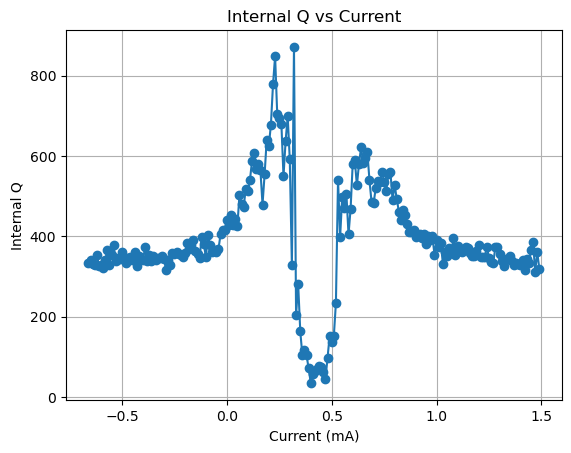

((3003,), 4699500000.0, 5499500000.0)

In [13]:
I = np.concatenate([I1_s1, I1_s2, I1_s3])
Ql = np.concatenate([Ql_1, Ql_2, Ql_3])
Qc = np.concatenate([Qc_1, Qc_2, Qc_3])
Qi = np.concatenate([Qi_1, Qi_2, Qi_3])
f0_shift = np.concatenate([fr_1, fr_2, fr_3])
Freq = np.concatenate([Freq_f1, Freq_f2, Freq_f3])
phi_0 = np.concatenate([phi_0_1, phi_0_2, phi_0_3])
plt.plot(I, Qi, '-o')
# # plt.plot(I1_s2, Ql_2, '-o')
# # plt.plot(I1_s3, Ql_3, '-o')
plt.xlabel('Current (mA)')
plt.ylabel('Internal Q')
plt.title('Internal Q vs Current')
plt.grid(True)
#plt.legend(])
plt.show()
Freq.shape, Freq.min(), Freq.max()

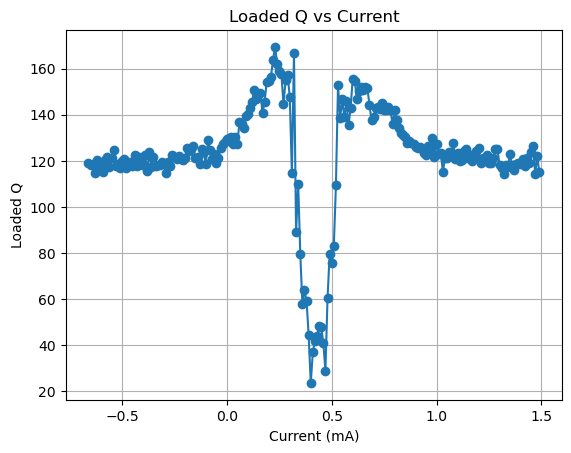

In [30]:
plt.plot(I, Ql, '-o')
# # plt.plot(I1_s2, Ql_2, '-o')
# # plt.plot(I1_s3, Ql_3, '-o')
plt.xlabel('Current (mA)')
plt.ylabel('Loaded Q')
plt.title('Loaded Q vs Current')
plt.grid(True)
#plt.legend(])
plt.show()

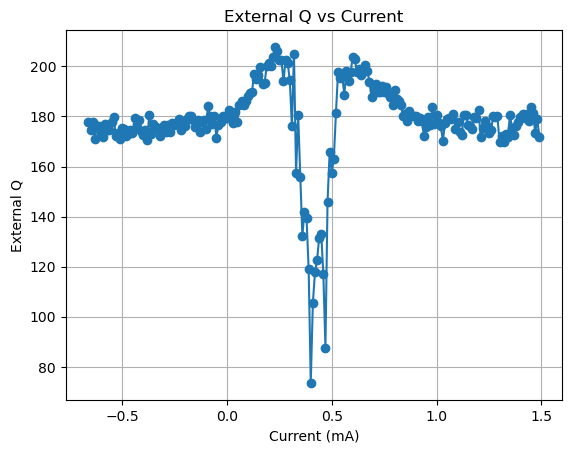

In [34]:
plt.plot(I, Qc, '-o')
plt.xlabel('Current (mA)')
plt.ylabel('External Q')
plt.title('External Q vs Current')
plt.grid(True)
#plt.legend(['Trace 1', 'Trace 2', 'Trace 3'])
plt.show()

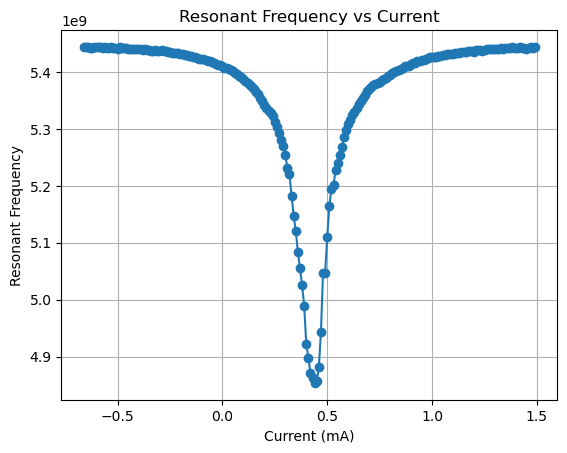

In [35]:
plt.plot(I, f0_shift, '-o')
plt.xlabel('Current (mA)')
plt.ylabel('Resonant Frequency')
plt.title('Resonant Frequency vs Current')
plt.grid(True)
#plt.legend(['Trace 1', 'Trace 2', 'Trace 3'])
plt.show()

In [14]:
from scipy.special import ellipk
from scipy.signal import find_peaks, peak_widths
from scipy.constants import mu_0, epsilon_0
from scipy.optimize import root, curve_fit
from functools import partial
from scipy.io import loadmat
from scipy.optimize import least_squares

In [15]:
def del_sol(delta, a, phi_ext_val):
    
    lhs = delta + a * np.sin(delta)
    
    return lhs - phi_ext_val


# calculates the impedance of the coupling capacitor to the transmission line (not shown in the setup)
def c_cap(c_c, w):
    return np.array([[1,1/(1j*c_c*w)],[0,1]])

# calculates the impedance of the resonator
def tline(Z0, beta, L):
    return np.array([[np.cos(beta*L),1j*Z0*np.sin(beta*L)],[1j*(1/Z0)*np.sin(beta*L),np.cos(beta*L)]])


def Z_L(L_01, L_02, L_T, d, w, R):
    # R_n = (L_T*np.pi**2*delta_0)/(elec_c*phi_0)
    ZL01 = 1j*w*L_01
    ZL02 = 1j*w*L_02
    ZLT = 1j*w*L_T/np.cos(d)
    # ZCT = 1/(1j*w*CT)
    Z_squid = ZLT #(1/ZLT + 1/ZCT + 1/R_n)**(-1)
    ZL02R = (1/ZL02 + 1/R)**(-1)
    ZSQUID = (1/ZL01 + 1/(Z_squid + ZL02R))**(-1)
    
    return ZSQUID

def Z_tot(ZL, Z0, beta, l, c_c, w):
    x = beta*l
    Z_c = 1/(1j*w*c_c)
    return (Z0*((ZL + 1j*Z0*np.tan(x))/(Z0 + 1j*ZL*np.tan(x)))) + Z_c

def branch(Z):
    return np.array([[1,0], [1/Z, 1]])
    
#calculates the ABCD matrix
def ABCD(M1, M2, M3):
    full_M = M1 @ M2 @ M3 
    
    return full_M
#Calculates the S21 parameter
def S21(A, B, C, D, Z0):
    return 2/(A + B/Z0 + C*Z0 + D)


def current_to_flux(I, M, o):
    return M*I + o


In [16]:
def solve_delta(phi_ext, a):
    phi_ext = np.asarray(phi_ext)
    delta = np.zeros_like(phi_ext, dtype=float)
    order = np.argsort(phi_ext)          # continuity in phi_ext, not array position
    d0 = 0.0
    for idx in order:
        sol = root(del_sol, d0, args=(a, phi_ext[idx]))
        delta[idx] = sol.x[0]
        d0 = sol.x[0]
    return delta

def S21_fit_func(X, L0, LT, L_l, C_l, C_c, R_j, M, O, l_f, Z0=50):
    """
    X = (I, f): current (A) and frequency (Hz) arrays, same length (elementwise pairs).
    Fit params: L0 (=L01=L02), LT, L_l, C_l, C_c, R_j
    Fixed:      l_f (resonator length), M, O (current -> flux calibration)
    """
    I, f = X
    w = 2 * np.pi * f
    phi_ext = M * I + O #np.pi - 0.5 -0.25 - 0.25 - 0.25

    a = 2 * L0 / LT
    delta = solve_delta(phi_ext, a)

    beta = w * np.sqrt(L_l * C_l)
    ZL = Z_L(L0, L0, LT, delta, w, R_j)
    Ztot = Z_tot(ZL, Z0, beta, l_f, C_c, w)

    return 2 / (2 + Z0 / Ztot)

def S21_fit_mag_dB(X, L0, LT, L_l, C_l, C_c, R_j, M, O, l_f):
    S21 = S21_fit_func(X, L0, LT, L_l, C_l, C_c, R_j, M, O, l_f)
    return 20 * np.log10(np.abs(S21))

In [29]:
def calc_cpw_param_set(
    center_width: float, gap_width: float, substrate_r: float, metal_thickness: float
):
    a = center_width / 2
    b = center_width / 2 + gap_width
    d = metal_thickness / (2 * np.pi)

    u1 = (
        a
        + d / 2
        + 3 / 2 * np.log(2) * d
        - d / 2 * np.log(d / a)
        + d / 2 * np.log((b - a) / (a + b))
    )
    u2 = (
        b
        - d / 2
        - 3 / 2 * np.log(2) * d
        + d / 2 * np.log(d / a)
        + d / 2 * np.log((b - a) / (a + b))
    )
    k1 = u1 / u2
    k2 = np.sqrt(1 - k1**2)
    c = 2 * epsilon_0 * ellipk(k1) / ellipk(k2) * (1 + substrate_r)

    d = d/2
    u1 = a+d/2+3/2*np.log(2)*d-d/2*np.log(d/a)+d/2*np.log((b-a)/(a+b))
    u2 = b-d/2-3/2*np.log(2)*d+d/2*np.log(d/a)+d/2*np.log((b-a)/(a+b))
    k1 = u1/u2
    k2 = np.sqrt(1-k1**2)
    l = mu_0/4*ellipk(k2)/ellipk(k1)

    lambda_eff = 50e-9  # m, effective field penetration depth
    k = a/b
    g_ctr = 1/(4*a*ellipk(k)**2*(1-k)**2) * \
        (np.pi+np.log(4*np.pi*a/metal_thickness)-k*np.log((1+k)/(1-k)))
    g_gnd = 1/(4*a*ellipk(k)**2*(1-k)**2) * \
        (np.pi+np.log(4*np.pi*b/metal_thickness)-k*np.log((1+k)/(1-k)))
    g = g_ctr+g_gnd
    l_ki = g*mu_0*lambda_eff
    l_tot = l+l_ki

    return {'inductance': l_tot, 'capacitance': c}

def calc_target_length(target_frequency: float, cpw_param_set: dict):
    return 1e6 / (4 * target_frequency * np.sqrt(cpw_param_set['inductance'] * cpw_param_set['capacitance']))



def calc_target_frequency(target_length: float, cpw_param_set: dict):
    return 1e6 / (4 * target_length * np.sqrt(cpw_param_set['inductance'] * cpw_param_set['capacitance']))



resonator_widths = [7, 10, 7]
#################################3

res_cpw_param_set = calc_cpw_param_set(
    center_width= resonator_widths[1]*1e-6, 
    gap_width=resonator_widths[0]*1e-6, 
    substrate_r=11.6, 
    metal_thickness=200e-9
)
l = calc_target_length(5.5e9, res_cpw_param_set)
R_L = l/1e6
# C_l = 1.285e-10
C_c = 35e-15
L_l = res_cpw_param_set['inductance']
C_l = res_cpw_param_set['capacitance']
L01_L = 394 * 1e-6
L02_L = 394 * 1e-6
#R_L
Z0_test = np.sqrt(L_l/C_l)
Z0_test
# l_test = calc_target_length(7e9, res_cpw_param_set)
R_L

0.005122618693766043

In [18]:
def lorentzian_dip_power(f, f0, Q_L, baseline, Q_e_inv):
    """
    Fit model for |S21|^2 in terms of Q factors directly.
    Q_e_inv = 1/Q_e (easier to fit as a free parameter)
    """
    depth_amplitude = Q_L * Q_e_inv          # = Q_L / Q_e
    lorentz = depth_amplitude / (1 + 4 * Q_L**2 * ((f - f0)/f0)**2)
    # |S21|^2 = baseline * |1 - lorentz|^2
    return baseline * (1 - lorentz)**2


# Drop-in replacement for calculate_q_factors in cell 26 (keep your lorentzian_dip_power as is).
# Default behaviour (plot=False) is identical to your current version.
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit


def calculate_q_factors(freq, S21_vals, min_pts=2,
                        plot=False, n_plot=16, plot_idx=None, labels=None):
    """Same extraction/rejection logic as before.  With plot=True it also shows a grid of
    traces (all rejected ones first, remaining slots filled with evenly spaced accepted ones)
    so the Lorentzian fits can be judged by eye.  Rejected traces are still fitted for display
    (when possible), but their results are NOT returned.
      plot_idx : explicit list of trace indices to show (overrides the automatic choice)
      labels   : per-trace labels for the titles, e.g. the current array
    """
    n = S21_vals.shape[1]
    q_loaded, q_internal, q_external, f0_fits = (np.full(n, np.nan) for _ in range(4))
    df = freq[1] - freq[0]
    diag = {}

    for i in range(n):
        power = np.abs(S21_vals[:, i])**2
        d = diag[i] = dict(status='ok', k=None, base=None, half=None, below=None, p0=None, popt=None)
        k = np.argmin(power)
        d['k'] = k
        if k == 0 or k == len(freq) - 1:
            d['status'] = 'REJECTED: dip at window edge (no f0)'
            continue                                   # dip at window edge: no f0, no Q

        y0, y1, y2 = power[k-1], power[k], power[k+1]  # f0: parabolic interpolation, always available
        den = y0 - 2*y1 + y2
        f0_fits[i] = freq[k] + (0.5*(y0 - y2)/den*df if den != 0 else 0.0)

        base = power.max()
        half = base - (base - y1)/2
        below = np.where(power < half)[0]
        d.update(base=base, half=half, below=below)

        reason = None
        if len(below) < min_pts:
            reason = f'REJECTED: unresolved ({len(below)} pts below half-depth, need >= {min_pts})'
        elif len(below) > len(freq)//1.25:
            reason = f'REJECTED: too broad ({len(below)} pts below half-depth, max {len(freq)//1.25})'
        if reason is not None and not plot:
            continue                                   # unresolved or too broad: skip Q only

        df_guess = freq[below[-1]] - freq[below[0]] if len(below) > 1 else 0.0
        if df_guess <= 0:
            df_guess = 3*df                            # only reachable for rejected traces in plot mode
        QL0 = freq[k]/df_guess
        dip = np.clip(1 - np.sqrt(y1/base), 1e-6, 0.99)
        p0 = [freq[k], QL0, base, dip/QL0]
        d['p0'] = p0
        try:
            popt, _ = curve_fit(lorentzian_dip_power, freq, power, p0=p0, maxfev=2000)
        except (RuntimeError, ValueError):
            d['status'] = reason or 'REJECTED: curve_fit failed (maxfev / invalid)'
            continue
        d['popt'] = popt
        f0_fit, QL, _, QeInv = popt
        QL, Qe = abs(QL), 1/abs(QeInv)
        d['QL'], d['Qe'] = QL, Qe
        if reason is None:
            if abs(f0_fit - freq[k]) > 5*df_guess:
                reason = f'REJECTED: runaway f0 (|f0_fit - f_min| = {abs(f0_fit-freq[k])/df_guess:.1f} x FWHM guess)'
            elif not (1/QL - 1/Qe) > 0:
                reason = f'REJECTED: Q_L/Q_e = {QL/Qe:.2f} >= 1'
        if reason is not None:
            d['status'] = reason
            continue
        q_loaded[i], q_external[i] = QL, Qe
        q_internal[i] = 1/(1/QL - 1/Qe)

    if plot:
        _plot_q_diagnostics(freq, S21_vals, diag, f0_fits, q_internal, plot_idx, n_plot, labels)
    return q_loaded, q_internal, q_external, f0_fits


def _plot_q_diagnostics(freq, S21_vals, diag, f0_fits, q_internal, plot_idx, n_plot, labels):
    n = S21_vals.shape[1]
    if plot_idx is None:
        bad = np.where(~np.isfinite(q_internal))[0]
        good = np.where(np.isfinite(q_internal))[0]
        if len(bad) >= n_plot:
            pick = bad[np.linspace(0, len(bad)-1, n_plot).astype(int)]
        else:
            n_good = min(n_plot - len(bad), len(good))
            gpick = good[np.linspace(0, len(good)-1, n_good).astype(int)] if n_good > 0 else []
            pick = np.concatenate([bad, gpick])
        plot_idx = np.unique(pick).astype(int)
        print(f"{len(bad)} of {n} traces rejected: {bad.tolist()}")
    plot_idx = list(plot_idx)

    ncols = 4
    nrows = int(np.ceil(len(plot_idx)/ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.2*ncols, 3.3*nrows), squeeze=False)
    f_dense = np.linspace(freq.min(), freq.max(), 3000)
    for ax, i in zip(axes.ravel(), plot_idx):
        d = diag[i]
        power = np.abs(S21_vals[:, i])**2
        ok = d['status'] == 'ok'
        ax.plot(freq/1e9, power, '.-', color='0.55', ms=3, lw=0.6, label='data')
        if d['below'] is not None and len(d['below']):
            ax.plot(freq[d['below']]/1e9, power[d['below']], 'o', color='orange', ms=3, label='below half-depth')
            ax.axhline(d['half'], color='orange', ls=':', lw=0.8)
        if d['p0'] is not None:
            ax.plot(f_dense/1e9, lorentzian_dip_power(f_dense, *d['p0']), '--', color='tab:blue', lw=0.9, label='initial guess')
        txt = ''
        if d['popt'] is not None:
            ax.plot(f_dense/1e9, lorentzian_dip_power(f_dense, *d['popt']), '-', color='tab:red', lw=1.2, label='fit')
            txt = f"Q_L={d['QL']:.0f}  Q_e={d['Qe']:.0f}\nf0_fit={d['popt'][0]/1e9:.4f} GHz"
        if np.isfinite(f0_fits[i]):
            ax.axvline(f0_fits[i]/1e9, color='k', ls=':', lw=0.7)
        lab = f"I={labels[i]:.4g}" if labels is not None else ""
        ax.set_title(f"#{i} {lab}\n{d['status']}", fontsize=8, color=('green' if ok else 'red'))
        if txt:
            ax.text(0.02, 0.04, txt, transform=ax.transAxes, fontsize=7, va='bottom',
                    bbox=dict(fc='w', ec='0.8', alpha=0.8))
        ax.tick_params(labelsize=7); ax.grid(alpha=0.3)
    for ax in axes.ravel()[len(plot_idx):]:
        ax.set_visible(False)
    axes[0, 0].legend(fontsize=6, loc='upper right')
    for ax in axes[-1]:
        ax.set_xlabel('f (GHz)', fontsize=8)
    fig.suptitle('Lorentzian fits of |S21|^2  (green = accepted, red = rejected)', fontsize=10)
    plt.tight_layout()
    plt.show()


# ---- diagnostic for the MODEL traces (does not touch model_q_factors) ----
def diagnose_model_q(I_arr, L01, L02, a, L_l, C_l, C_c, R_j, M, O, l_f, f_bounds,
                     n_freq=1000, Z0=50, **plot_kw):
    """Builds the same first-pass |S21| grid as model_q_factors and plots the Lorentzian fits.
    Example:
      diagnose_model_q(I_plot_A, a_f*LT_f/2, LT_f, Ll_f, Cl_f, Cc_f, Rj_f, M_f, O_f, R_L,
                       (Freq.min(), Freq.max()), labels=I_plot_uA)
    """
    I_arr = np.asarray(I_arr)
    LT = (L01+L02)/a
    f_dense = np.linspace(*f_bounds, n_freq)
    delta = solve_delta(M*I_arr + O, (L01+L02)/LT)
    def S_of(d, f):
        w = 2*np.pi*f
        beta = w*np.sqrt(L_l*C_l)
        return 2/(2 + Z0/Z_tot(Z_L(L01, L02, LT, d, w, R_j), Z0, beta, l_f, C_c, w))
    S_grid = np.column_stack([S_of(d, f_dense) for d in delta])
    return calculate_q_factors(f_dense, S_grid, plot=True, **plot_kw)



def diagnose_model_q_fixed(I_arr, L_a, a, L_l, R_j, M, O, L01_L, L02_L, C_l, C_c, l_f, f_bounds,
                     n_freq=1000, Zport = 50.0,  **plot_kw):
    """Builds the same first-pass |S21| grid as model_q_factors and plots the Lorentzian fits.
    Example:
      diagnose_model_q(I_plot_A, a_f*LT_f/2, LT_f, Ll_f, Cl_f, Cc_f, Rj_f, M_f, O_f, R_L,
                       (Freq.min(), Freq.max()), labels=I_plot_uA)
    """
    I_arr = np.asarray(I_arr)
    Z0 = np.sqrt(L_l/C_l)
    L01 = L_l * L01_L + L_a
    L02 = L_l * L02_L
    LT = (L01+L02)/a
    f_dense = np.linspace(*f_bounds, n_freq)
    delta = solve_delta(M*I_arr + O, (L01+L02)/LT)
    def S_of(d, f):
        w = 2*np.pi*f
        beta = w*np.sqrt(L_l*C_l)
        return 2/(2 + Zport/Z_tot(Z_L(L01, L02, LT, d, w, R_j), Z0, beta, l_f, C_c, w))
    S_grid = np.column_stack([S_of(d, f_dense) for d in delta])
    return calculate_q_factors(f_dense, S_grid, plot=True, **plot_kw)

In [19]:
def model_q_factors(I_arr, L01, L02, a, L_l, C_l, C_c, R_j, M, O, l_f, f_bounds, n_freq=1000, Zport=50):
    Z0 = np.sqrt(L_l/C_l)
    I_arr = np.asarray(I_arr)
    LT = (L01+L02)/a
    f_dense = np.linspace(*f_bounds, n_freq)
    delta = solve_delta(M*I_arr + O, (L01+L02)/LT)

    def S_of(d, f):
        w = 2*np.pi*f
        beta = w*np.sqrt(L_l*C_l)
        return 2/(2 + Zport/Z_tot(Z_L(L01, L02, LT, d, w, R_j), Z0, beta, l_f, C_c, w))

    S_grid = np.column_stack([S_of(d, f_dense) for d in delta])
    q_L, q_i, q_e, f0 = calculate_q_factors(f_dense, S_grid)

    # retry failed points on windows centred on f0, widening until the Lorentzian fit is accepted
    for k in np.where(~np.isfinite(q_i) & np.isfinite(f0))[0]:
        for span in (2e6, 10e6, 50e6, 200e6, 600e6, 800e6, 1e9):
            f_z = np.linspace(f0[k] - span, f0[k] + span, 1000)
            qL, qi, qe, f0z = calculate_q_factors(f_z, S_of(delta[k], f_z)[:, None])
            if np.isfinite(qi[0]):
                q_L[k], q_i[k], q_e[k], f0[k] = qL[0], qi[0], qe[0], f0z[0]
                break
    return q_L, q_i, q_e, f0



def model_q_factors_fixed(I_arr, L_a, a, L_l,R_j, M, O, L01_L, L02_l, C_l, C_c, l_f, f_bounds, n_freq=1000, Zport = 50.0):
    Z0 = np.sqrt(L_l/C_l)
    L01 = L_l * L01_L + L_a
    L02 = L_l * L02_l
    I_arr = np.asarray(I_arr)
    LT = (L01+L02)/a
    f_dense = np.linspace(*f_bounds, n_freq)
    delta = solve_delta(M*I_arr + O, (L01+L02)/LT)

    def S_of(d, f):
        w = 2*np.pi*f
        beta = w*np.sqrt(L_l*C_l)
        return 2/(2 + Zport/Z_tot(Z_L(L01, L02, LT, d, w, R_j), Z0, beta, l_f, C_c, w))

    S_grid = np.column_stack([S_of(d, f_dense) for d in delta])
    q_L, q_i, q_e, f0 = calculate_q_factors(f_dense, S_grid)

    # retry failed points on windows centred on f0, widening until the Lorentzian fit is accepted
    for k in np.where(~np.isfinite(q_i) & np.isfinite(f0))[0]:
        for span in (2e6, 10e6, 50e6, 200e6, 600e6, 800e6, 1e9):
            f_z = np.linspace(f0[k] - span, f0[k] + span, 1000)
            qL, qi, qe, f0z = calculate_q_factors(f_z, S_of(delta[k], f_z)[:, None])
            if np.isfinite(qi[0]):
                q_L[k], q_i[k], q_e[k], f0[k] = qL[0], qi[0], qe[0], f0z[0]
                break
    return q_L, q_i, q_e, f0

In [20]:
import numpy as np
from scipy.optimize import root

# Needs these from your notebook: solve_delta, Z_L, Z_tot  (same ones model_q_factors uses)

def model_q_poles(I_arr, L01, L02, a, L_l, C_l, C_c, R_j, M, O, l_f,
                  f_center, span=300e6, n_scan=1500, Zport=50):
    """
    Model Q factors from the complex poles of S21 (no Lorentzian fit, no grid, no rejection logic).
      Q_L : pole with the real R_j          (loaded Q)
      Q_e : pole with R_j -> 0 (lossless)   (coupling Q)
      Q_i : 1 / (1/Q_L - 1/Q_e)
    f_center : array (same length as I_arr), e.g. your data f0 (fr_v2); the dip is searched in +-span.
    Returns q_L, q_i, q_e, f0 (NaN where no interior dip / pole not found).
    """
    I_arr = np.atleast_1d(np.asarray(I_arr, float))
    f_center = np.broadcast_to(np.asarray(f_center, float), I_arr.shape)
    LT = (L01 + L02) / a
    delta = solve_delta(M * I_arr + O, (L01 + L02) / LT)
    Z0 = np.sqrt(L_l/C_l)

    def Zc(f, d, R):                                   # f may be complex
        w = 2 * np.pi * f
        beta = w * np.sqrt(L_l * C_l)
        return Z_tot(Z_L(L01, L02, LT, d, w, R), Z0, beta, l_f, C_c, w)

    def pole(d, R, f_start):
        def F(x):
            v = Zc(x[0] + 1j * x[1], d, R) + Zport / 2    # S21 pole: Z_tot = -Z0/2
            return [v.real, v.imag]
        s = root(F, [f_start, -f_start / 1500], method="hybr", tol=1e-12)
        fr, fi = s.x
        if (not s.success) or abs(fr - f_start) > 50e6 or fi == 0:
            return np.nan, np.nan
        return fr, fr / (2 * abs(fi))

    n = I_arr.size
    q_L, q_i, q_e, f0 = (np.full(n, np.nan) for _ in range(4))
    for k in range(n):
        f = np.linspace(f_center[k] - span, f_center[k] + span, n_scan)
        s = np.abs(Zc(f, delta[k], R_j) / (Zc(f, delta[k], R_j) + Zport / 2)) ** 2   # |S21|^2 up to a constant factor
        j = np.argmin(s)
        if j == 0 or j == n_scan - 1:
            continue                                   # no interior dip
        fr, QL = pole(delta[k], R_j, f[j])
        fr0, Qe = pole(delta[k], 1e-9, fr if np.isfinite(fr) else f[j])
        if not (np.isfinite(QL) and np.isfinite(Qe)):
            continue
        f0[k], q_L[k], q_e[k] = fr, QL, Qe
        inv = 1 / QL - 1 / Qe
        if inv > 0:
            q_i[k] = 1 / inv
    return q_L, q_i, q_e, f0

In [21]:
def model_q_poles_fixed(I_arr, L_a, a, L_l, R_j, M, O, L01_L, L02_L, C_l, C_c, l_f,
                  f_center, span=800e6, n_scan=1500, Zport = 50.0):
    """
    Model Q factors from the complex poles of S21 (no Lorentzian fit, no grid, no rejection logic).
      Q_L : pole with the real R_j          (loaded Q)
      Q_e : pole with R_j -> 0 (lossless)   (coupling Q)
      Q_i : 1 / (1/Q_L - 1/Q_e)
    f_center : array (same length as I_arr), e.g. your data f0 (fr_v2); the dip is searched in +-span.
    Returns q_L, q_i, q_e, f0 (NaN where no interior dip / pole not found).
    """

    Z0 = np.sqrt(L_l/C_l)
    I_arr = np.atleast_1d(np.asarray(I_arr, float))
    f_center = np.broadcast_to(np.asarray(f_center, float), I_arr.shape)
    L01 = L_l * L01_L + L_a
    L02 = L_l * L02_L
    LT = (L01 + L02) / a
    delta = solve_delta(M * I_arr + O, (L01 + L02) / LT)

    def Zc(f, d, R):                                   # f may be complex
        w = 2 * np.pi * f
        beta = w * np.sqrt(L_l * C_l)
        return Z_tot(Z_L(L01, L02, LT, d, w, R), Z0, beta, l_f, C_c, w)

    def pole(d, R, f_start):
        def F(x):
            v = Zc(x[0] + 1j * x[1], d, R) + Zport / 2    # S21 pole: Z_tot = -Z0/2
            return [v.real, v.imag]
        s = root(F, [f_start, -f_start / 1500], method="hybr", tol=1e-12)
        fr, fi = s.x
        if (not s.success) or abs(fr - f_start) > 50e6 or fi == 0:
            return np.nan, np.nan
        return fr, fr / (2 * abs(fi))

    n = I_arr.size
    q_L, q_i, q_e, f0 = (np.full(n, np.nan) for _ in range(4))
    for k in range(n):
        f = np.linspace(f_center[k] - span, f_center[k] + span, n_scan)
        s = np.abs(Zc(f, delta[k], R_j) / (Zc(f, delta[k], R_j) + Zport / 2)) ** 2   # |S21|^2 up to a constant factor
        j = np.argmin(s)
        if j == 0 or j == n_scan - 1:
            continue                                   # no interior dip
        fr, QL = pole(delta[k], R_j, f[j])
        fr0, Qe = pole(delta[k], 1e-9, fr if np.isfinite(fr) else f[j])
        if not (np.isfinite(QL) and np.isfinite(Qe)):
            continue
        f0[k], q_L[k], q_e[k] = fr, QL, Qe
        inv = 1 / QL - 1 / Qe
        if inv > 0:
            q_i[k] = 1 / inv
    return q_L, q_i, q_e, f0

In [23]:
I.shape

(216,)

In [30]:
PENALTY_F0 = 500.0     # MHz
F0_SCALE = 20.0        # MHz, tolerance
QI_SCALE = 0.1         # log10 units, tolerance

def summary_residuals_QL_f0_pole(params, I_arr, Qi_data, f0_data, l_f, f_bounds):
    L01, L02, a, L_l, C_l, C_c, R_j, M, O, Q_alpha = params
    #LT = (L01+L02)/a
    n = len(I_arr)
    try:
        # q_L, q_i, q_e, f0 = model_q_factors(I_arr, L01, L02, a, L_l, C_l, C_c, R_j, M, O, l_f, f_bounds)
        q_L, q_i, q_e, f0 = model_q_poles(I_arr, L01, L02, a, L_l, C_l, C_c, R_j, M, O, l_f, f_center=f0_data)
    except Exception as e:
        print("model failed:", repr(e))              # don't swallow errors silently
        return np.full(2*n, PENALTY_F0 / F0_SCALE)

    res_f0 = np.where(np.isfinite(f0), (f0 - f0_data)/1e6, PENALTY_F0) / F0_SCALE

    res_Qi = np.zeros(n)                              # unresolved points: no contribution
    okq = np.isfinite(q_i) & (q_i > 0) & np.isfinite(Qi_data)
    res_Qi[okq] = (np.log10(1/(1/q_i[okq] + 1/Q_alpha)) - np.log10(Qi_data[okq])) / QI_SCALE
    return np.concatenate([res_Qi, res_f0])


def summary_residuals_QL_f0(params, I_arr, Qi_data, f0_data, l_f, f_bounds):
    L01, L02, a, L_l, C_l, C_c, R_j, M, O, Q_alpha = params
    #LT = (L01+L02)/a
    n = len(I_arr)
    try:
        q_L, q_i, q_e, f0 = model_q_factors(I_arr, L01, L02, a, L_l, C_l, C_c, R_j, M, O, l_f, f_bounds)
        # q_L, q_i, q_e, f0 = model_q_poles(I_arr, L01, L02, a, L_l, C_l, C_c, R_j, M, O, l_f, f_center=f0_data)
    except Exception as e:
        print("model failed:", repr(e))              # don't swallow errors silently
        return np.full(2*n, PENALTY_F0 / F0_SCALE)

    res_f0 = np.where(np.isfinite(f0), (f0 - f0_data)/1e6, PENALTY_F0) / F0_SCALE

    res_Qi = np.zeros(n)                              # unresolved points: no contribution
    okq = np.isfinite(q_i) & (q_i > 0) & np.isfinite(Qi_data)
    res_Qi[okq] = (np.log10(1/(1/q_i[okq] + 1/Q_alpha)) - np.log10(Qi_data[okq])) / QI_SCALE
    return np.concatenate([res_Qi, res_f0])



def summary_residuals_QL_f0_pole_fixed(params, I_arr, Qi_data, f0_data, L01_L, L02_L, C_l, C_c, l_f, f_bounds):
    L_a, a, L_l, R_j, M, O, Q_alpha = params
    #LT = (L01+L02)/a
    n = len(I_arr)
    # L01 = L_l * L01_L
    # L02 = L_l * L02_L
    try:
        # q_L, q_i, q_e, f0 = model_q_factors(I_arr, L01, L02, a, L_l, C_l, C_c, R_j, M, O, l_f, f_bounds)
        q_L, q_i, q_e, f0 = model_q_poles_fixed(I_arr, L_a, a, L_l, R_j, M, O, L01_L, L02_L, C_l, C_c, l_f, f_center=f0_data)
    except Exception as e:
        print("model failed:", repr(e))              # don't swallow errors silently
        return np.full(2*n, PENALTY_F0 / F0_SCALE)

    res_f0 = np.where(np.isfinite(f0), (f0 - f0_data)/1e6, PENALTY_F0) / F0_SCALE

    res_Qi = np.zeros(n)                              # unresolved points: no contribution
    okq = np.isfinite(q_i) & (q_i > 0) & np.isfinite(Qi_data)
    res_Qi[okq] = (np.log10(1/(1/q_i[okq] + 1/Q_alpha)) - np.log10(Qi_data[okq])) / QI_SCALE
    return np.concatenate([res_Qi, res_f0])


O_guess = np.pi - 1.25
M_mag = 2*np.pi / np.abs(((I.min() -I.max())*1e-6))
#L_l = 4.9137e-7
#C_l = 1.2861e-10
M_mag

2922411.7707812027

In [25]:
p0_fixed = [0.05e-9, 0.9, 1.1*L_l, 5, M_mag, O_guess,850]
lower_fixed = [0.01e-9, 0.6, 0.5*L_l, 1,  -1.1*M_mag, -np.pi, 800]
upper_fixed = [0.1e-9, 0.99, 1.5*L_l, 30, 1.1*M_mag, np.pi, 5e3]


best = None
for O in np.linspace(2.4, np.pi, 8):
    for Mf in (0.7, 0.8, 0.9, 1.0, 1.1):
        for a_ in (0.9, 0.95, 0.98):
            p = list(p0_fixed); p[5] = O; p[4] = Mf*M_mag; p[1] = a_
            _, _, _, f0m = model_q_poles_fixed(I*1e-6, *p[:6], L01_L, L02_L, C_l, C_c, R_L, f_center=f0_shift)
            c = np.sum(np.where(np.isfinite(f0m),
                                ((f0m - f0_shift)/1e6/F0_SCALE)**2,
                                (PENALTY_F0/F0_SCALE)**2))
            if best is None or c < best[0]:
                best = (c, p)
p0_fixed = best[1]
lower_fixed[5], upper_fixed[5] = 0, 2*np.pi        # old bound of π cut off the region near the answer
print("grid start: O =", p0_fixed[5], " M/M_mag =", p0_fixed[4]/M_mag, " a =", p0_fixed[1])

grid start: O = 3.141592653589793  M/M_mag = 0.7  a = 0.9


In [26]:
res_fixed = least_squares(
    summary_residuals_QL_f0_pole_fixed, p0_fixed,
    args=(I*1e-6, Qi, f0_shift, L01_L, L02_L, C_l, C_c, R_L, (Freq.min()-1e9, Freq.max()+1e9)),
    bounds=(lower_fixed, upper_fixed), x_scale='jac'
)
L_a_fixed, a_fixed, Ll_fixed, Rj_fixed, M_fixed, O_fixed, Q_alpha_fixed = res_fixed.x
print(res_fixed.x, " LT =", (L01_L*L_l + L_a_fixed + L02_L*L_l)/a_fixed, "L_l_fit/L_l =", Ll_fixed/L_l, " cost:", res_fixed.cost)

[4.10820226e-11 9.45285693e-01 5.66687417e-07 1.42363664e+00
 2.57747833e+06 3.77650000e+00 8.39206326e+02]  LT = 4.664469795802067e-10 L_l_fit/L_l = 1.1168107894387367  cost: 103073.78405596438


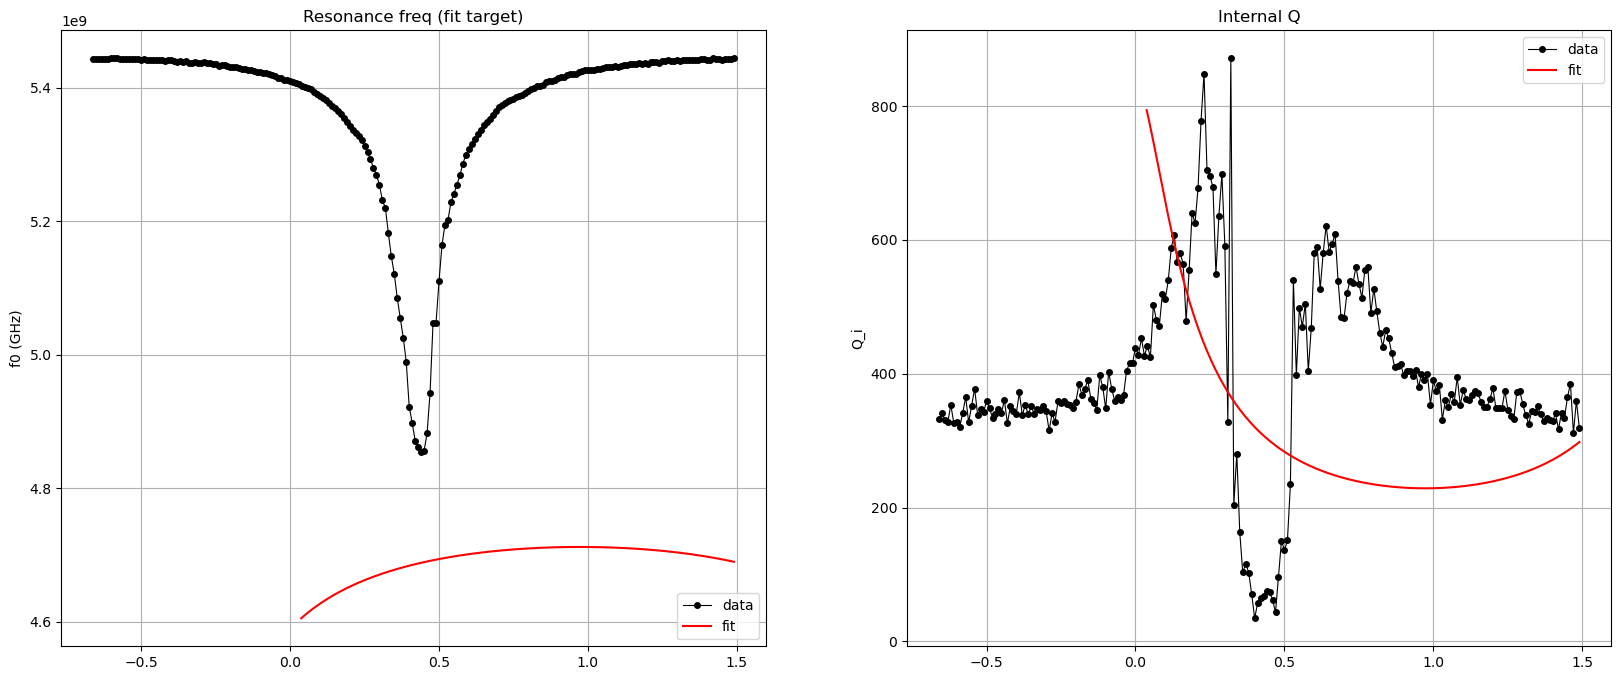

In [27]:
I_plot_uA = np.linspace(I.min(), I.max(), 300)
I_plot_A = I_plot_uA * 1e-6
m = np.isfinite(f0_shift)
f_c = np.interp(I_plot_uA, I[m], f0_shift[m])
QL_model_fixed, q_i_model_fixed, q_e_model_fixed, f0_model_fixed = model_q_poles_fixed(
    I_plot_A, L_a_fixed, a_fixed, Ll_fixed, Rj_fixed, M_fixed, O_fixed, L01_L, L02_L, C_l, C_c, R_L, f_center=f_c
)
Qi_total_model_fixed  = 1/(1/q_i_model_fixed + 1/Q_alpha_fixed)

fig, axes = plt.subplots(1, 2, figsize=(20, 8))
# axes[0,0].plot(I1_full, Ql_v2, 'ko-', ms=4, lw=0.8, label='data')
# axes[0,0].plot(I_plot_uA, QL_model, 'r-', lw=1.5, label='fit')
# axes[0,0].set_ylabel('Q_L'); axes[0,0].set_title('Loaded Q (fit target)'); axes[0,0].legend(); axes[0,0].grid(True)

axes[0].plot(I, f0_shift, 'ko-', ms=4, lw=0.8, label='data')
axes[0].plot(I_plot_uA, f0_model_fixed, 'r-', lw=1.5, label='fit')
axes[0].set_ylabel('f0 (GHz)'); axes[0].set_title('Resonance freq (fit target)'); axes[0].legend(); axes[0].grid(True)

#axes[1].plot(I1_full, Qi_fit, 'b-', ms=4, lw=0.8, label='data')
axes[1].plot(I, Qi, 'ko-', ms=4, lw=0.8, label='data')
axes[1].plot(I_plot_uA, Qi_total_model_fixed, 'r-', lw=1.5, label='fit')
axes[1].set_ylabel('Q_i'); axes[1].set_yscale('linear'); axes[1].set_title('Internal Q'); axes[1].legend(); axes[1].grid(True)

In [31]:
O_guess_2 = np.pi - 1.25
M_mag_2 = 2*np.pi / np.abs(((I.min() -I.max())*1e-6))
#L_l = 4.9137e-7
#C_l = 1.2861e-10

p0_2 = [0.2e-9, 0.2e-9, 0.9, 1.1*L_l, 1.1*C_l, 35e-15, 15, M_mag, O_guess, 850]
lower_2 = [0.15e-9, 0.15e-9, 0.7, 0.7*L_l, 0.7*C_l, 30e-15, 1,  -1.1*M_mag, -np.pi,  8e2]
upper_2 = [0.25e-9, 0.25e-9, 0.99, 1.5*L_l, 1.5*C_l, 40e-15, 30, 1.1*M_mag, np.pi, 1.5e3]

best_2 = None
for O in np.linspace(2.4, np.pi, 8):
    for Mf in (0.7, 0.8, 0.9, 1.0, 1.1):
        for a_ in (0.9, 0.95, 0.98):
            p = list(p0_2); p[8] = O; p[7] = Mf*M_mag; p[2] = a_
            _, _, _, f0m = model_q_poles(I*1e-6, *p[:9], R_L, f_center=f0_shift)
            c = np.sum(np.where(np.isfinite(f0m),
                                ((f0m - f0_shift)/1e6/F0_SCALE)**2,
                                (PENALTY_F0/F0_SCALE)**2))
            if best_2 is None or c < best_2[0]:
                best_2 = (c, p)
p0_2 = best_2[1]
lower_2[8], upper_2[8] = 0, 2*np.pi        # old bound of π cut off the region near the answer
print("grid start: O =", p0_2[8], " M/M_mag =", p0_2[7]/M_mag, " a =", p0_2[2])

grid start: O = 3.141592653589793  M/M_mag = 1.1  a = 0.98


In [32]:
res_2 = least_squares(
    summary_residuals_QL_f0, p0_2,
    args=(I*1e-6, Qi, f0_shift, R_L, (Freq.min()-1e9, Freq.max()+1e9)),
    bounds=(lower_2, upper_2), x_scale='jac'
)
L01_f_2, L02_f_2, a_f_2, Ll_f_2, Cl_f_2, Cc_f_2, Rj_f_2, M_f_2, O_f_2, Q_alpha_f_2 = res_2.x
print(res_2.x, " LT =", (L01_f_2 + L02_f_2)/a_f_2, "L_l_fit/L_l =", Ll_f_2/L_l, "C_l_fit/C_l =", Cl_f_2/C_l, " cost:", res_2.cost)

C:\ProgramData\anaconda3\Lib\site-packages\scipy\optimize\_lsq\trf.py:234: RuntimeWarning: divide by zero encountered in divide
  Delta = norm(x0 * scale_inv / v**0.5)
C:\ProgramData\anaconda3\Lib\site-packages\scipy\optimize\_lsq\trf.py:363: RuntimeWarning: invalid value encountered in scalar divide
  alpha *= Delta / Delta_new
C:\ProgramData\anaconda3\Lib\site-packages\scipy\optimize\_lsq\trf.py:363: RuntimeWarning: invalid value encountered in scalar multiply
  alpha *= Delta / Delta_new
C:\ProgramData\anaconda3\Lib\site-packages\scipy\optimize\_lsq\common.py:398: RuntimeWarning: invalid value encountered in cast
  return min_step, np.equal(steps, min_step) * np.sign(s).astype(int)


KeyboardInterrupt: 